<a href="https://colab.research.google.com/github/adibansal06/UCS420_CC_LabAssignments_1024170054/blob/main/Assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 – Cognitive Computing
## Lab Assignment 10: NLP using Python-II
### Feature Extraction from Text, Sentiment Analysis and Text Generation



## Setup: Install and import required libraries

In [1]:
%pip install -q nltk scikit-learn textblob wordcloud matplotlib tensorflow

In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from textblob import TextBlob
from wordcloud import WordCloud

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("Libraries imported and NLTK resources downloaded successfully.")

Libraries imported and NLTK resources downloaded successfully.


## Q1. Text preprocessing, tokenization and word frequency

**Paragraph (topic: Technology)**

Technology has changed the way people learn, communicate, and solve problems. Computers and smartphones provide quick access to information from almost anywhere. Artificial intelligence helps people analyse large amounts of data and automate repetitive tasks. However, technology should be used responsibly because privacy and security are important. I enjoy learning about new technologies because they encourage creativity and make everyday work more efficient.

In [3]:
paragraph = (
    "Technology has changed the way people learn, communicate, and solve problems. "
    "Computers and smartphones provide quick access to information from almost anywhere. "
    "Artificial intelligence helps people analyse large amounts of data and automate repetitive tasks. "
    "However, technology should be used responsibly because privacy and security are important. "
    "I enjoy learning about new technologies because they encourage creativity and make everyday work more efficient."
)

# 1. Lowercase and remove punctuation using re.
clean_text = re.sub(r"[^a-zA-Z0-9\\s]", "", paragraph.lower())
print("Original paragraph:\\n", paragraph)
print("\\nLowercase text without punctuation:\\n", clean_text)

Original paragraph:\n Technology has changed the way people learn, communicate, and solve problems. Computers and smartphones provide quick access to information from almost anywhere. Artificial intelligence helps people analyse large amounts of data and automate repetitive tasks. However, technology should be used responsibly because privacy and security are important. I enjoy learning about new technologies because they encourage creativity and make everyday work more efficient.
\nLowercase text without punctuation:\n technologyhaschangedthewaypeoplelearncommunicateandsolveproblemscomputersandsmartphonesprovidequickaccesstoinformationfromalmostanywhereartificialintelligencehelpspeopleanalyselargeamountsofdataandautomaterepetitivetaskshowevertechnologyshouldbeusedresponsiblybecauseprivacyandsecurityareimportantienjoylearningaboutnewtechnologiesbecausetheyencouragecreativityandmakeeverydayworkmoreefficient


In [4]:
# 2. Tokenize into words and sentences.
word_tokens = word_tokenize(clean_text)
sentence_tokens = sent_tokenize(paragraph)

print("Word tokens:")
print(word_tokens)
print("\\nSentence tokens:")
for i, sentence in enumerate(sentence_tokens, start=1):
    print(f"{i}. {sentence}")

Word tokens:
['technologyhaschangedthewaypeoplelearncommunicateandsolveproblemscomputersandsmartphonesprovidequickaccesstoinformationfromalmostanywhereartificialintelligencehelpspeopleanalyselargeamountsofdataandautomaterepetitivetaskshowevertechnologyshouldbeusedresponsiblybecauseprivacyandsecurityareimportantienjoylearningaboutnewtechnologiesbecausetheyencouragecreativityandmakeeverydayworkmoreefficient']
\nSentence tokens:
1. Technology has changed the way people learn, communicate, and solve problems.
2. Computers and smartphones provide quick access to information from almost anywhere.
3. Artificial intelligence helps people analyse large amounts of data and automate repetitive tasks.
4. However, technology should be used responsibly because privacy and security are important.
5. I enjoy learning about new technologies because they encourage creativity and make everyday work more efficient.


In [5]:
# 3. Compare split() and word_tokenize().
split_tokens = clean_text.split()
nltk_tokens = word_tokenize(clean_text)
print("Tokens using split():", split_tokens)
print("\\nTokens using word_tokenize():", nltk_tokens)
print("\\nToken counts:", len(split_tokens), "and", len(nltk_tokens))

Tokens using split(): ['technologyhaschangedthewaypeoplelearncommunicateandsolveproblemscomputersandsmartphonesprovidequickaccesstoinformationfromalmostanywhereartificialintelligencehelpspeopleanalyselargeamountsofdataandautomaterepetitivetaskshowevertechnologyshouldbeusedresponsiblybecauseprivacyandsecurityareimportantienjoylearningaboutnewtechnologiesbecausetheyencouragecreativityandmakeeverydayworkmoreefficient']
\nTokens using word_tokenize(): ['technologyhaschangedthewaypeoplelearncommunicateandsolveproblemscomputersandsmartphonesprovidequickaccesstoinformationfromalmostanywhereartificialintelligencehelpspeopleanalyselargeamountsofdataandautomaterepetitivetaskshowevertechnologyshouldbeusedresponsiblybecauseprivacyandsecurityareimportantienjoylearningaboutnewtechnologiesbecausetheyencouragecreativityandmakeeverydayworkmoreefficient']
\nToken counts: 1 and 1


**Comparison:** `split()` separates text at whitespace. NLTK's `word_tokenize()` is designed for natural-language token boundaries and handles punctuation more appropriately. Since punctuation was removed before this comparison, the outputs may be very similar.

In [6]:
# 4. Remove stopwords.
stop_words = set(stopwords.words("english"))
filtered_tokens = [word for word in nltk_tokens if word.isalpha() and word not in stop_words]
print("Tokens after stopword removal:")
print(filtered_tokens)

Tokens after stopword removal:
['technologyhaschangedthewaypeoplelearncommunicateandsolveproblemscomputersandsmartphonesprovidequickaccesstoinformationfromalmostanywhereartificialintelligencehelpspeopleanalyselargeamountsofdataandautomaterepetitivetaskshowevertechnologyshouldbeusedresponsiblybecauseprivacyandsecurityareimportantienjoylearningaboutnewtechnologiesbecausetheyencouragecreativityandmakeeverydayworkmoreefficient']


Word frequency distribution:
technologyhaschangedthewaypeoplelearncommunicateandsolveproblemscomputersandsmartphonesprovidequickaccesstoinformationfromalmostanywhereartificialintelligencehelpspeopleanalyselargeamountsofdataandautomaterepetitivetaskshowevertechnologyshouldbeusedresponsiblybecauseprivacyandsecurityareimportantienjoylearningaboutnewtechnologiesbecausetheyencouragecreativityandmakeeverydayworkmoreefficient: 1


/tmp/ipykernel_1812/2051483521.py:14: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


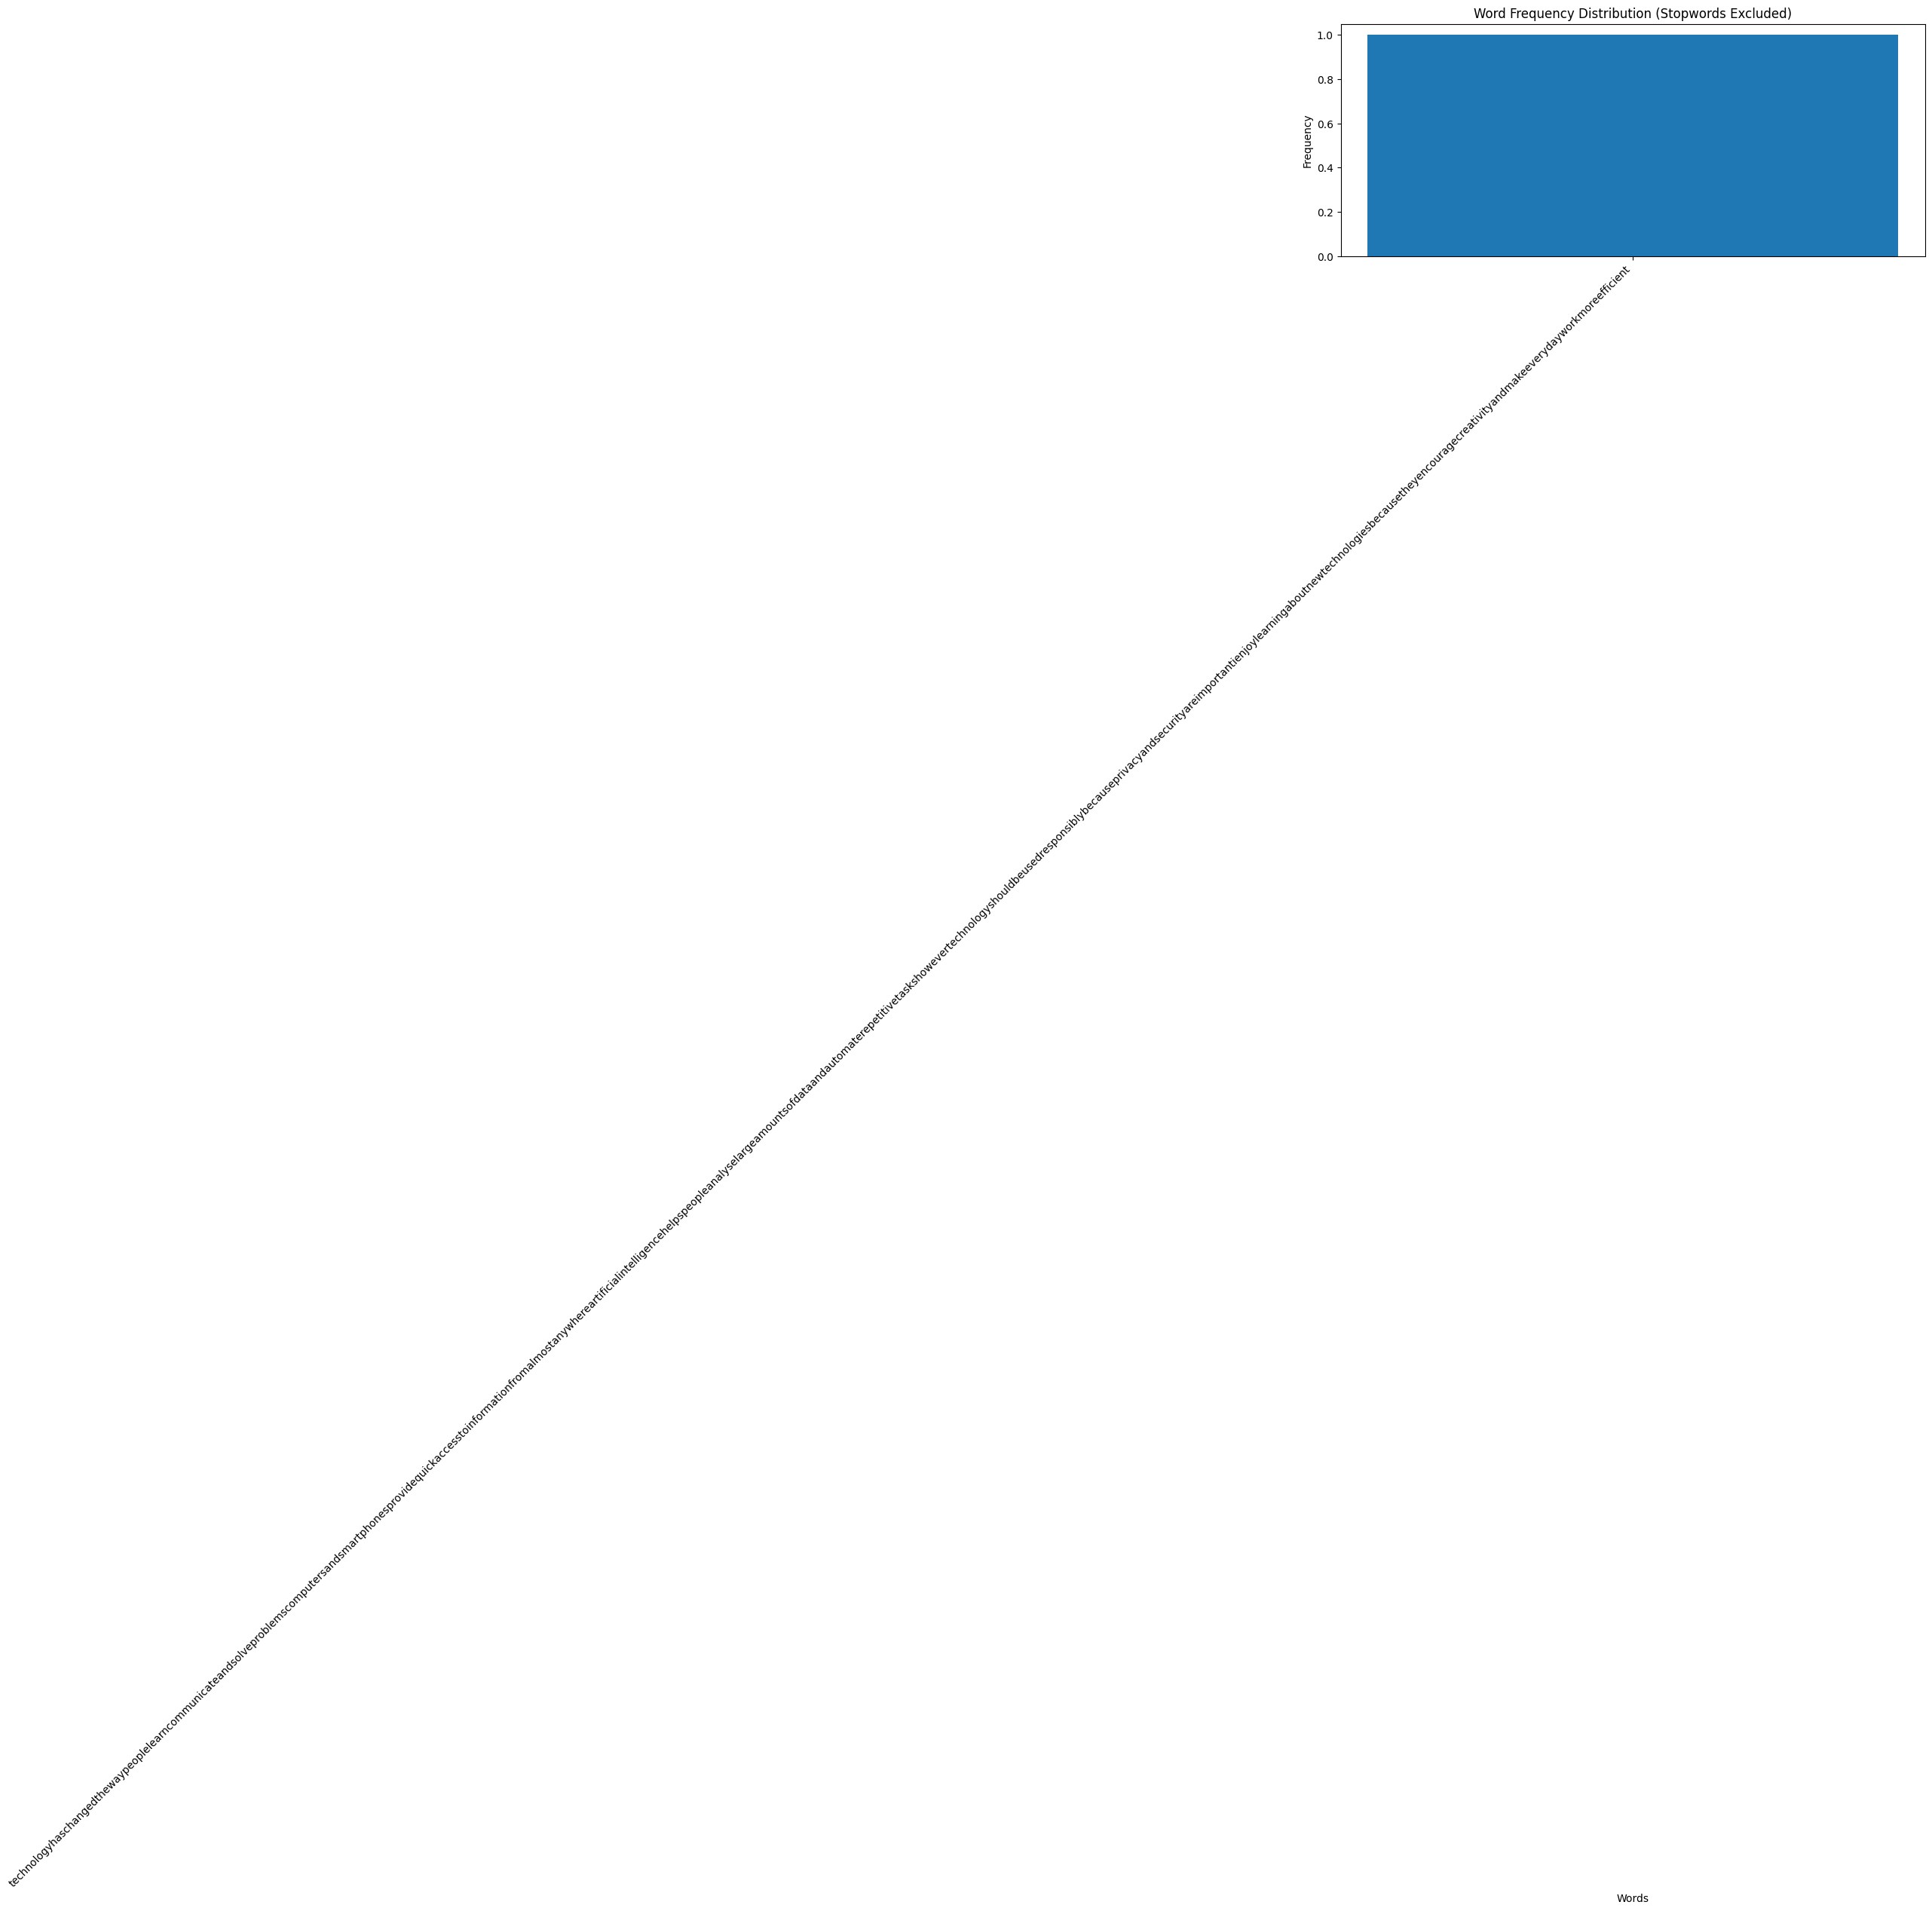

In [7]:
# 5. Word frequency distribution excluding stopwords.
frequency = Counter(filtered_tokens)
print("Word frequency distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

plt.figure(figsize=(10, 4))
words, counts = zip(*frequency.most_common())
plt.bar(words, counts)
plt.title("Word Frequency Distribution (Stopwords Excluded)")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Q2. Regular expressions, stemming and lemmatization

The same paragraph from Q1 is used.

In [8]:
# 1. Extract alphabet-only words using re.findall().
alphabet_words = re.findall(r"\\b[a-zA-Z]+\\b", paragraph.lower())
print("Alphabet-only words:", alphabet_words)

Alphabet-only words: []


In [9]:
# 2. Remove stopwords.
stop_words = set(stopwords.words("english"))
q2_filtered = [word for word in alphabet_words if word not in stop_words]
print("After stopword removal:", q2_filtered)

After stopword removal: []


In [10]:
# 3. Porter stemming and 4. WordNet lemmatization.
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stemmed_words = [stemmer.stem(word) for word in q2_filtered]
lemmatized_words = [lemmatizer.lemmatize(word) for word in q2_filtered]

print("Original words:", q2_filtered)
print("\\nStemmed words:", stemmed_words)
print("\\nLemmatized words:", lemmatized_words)

Original words: []
\nStemmed words: []
\nLemmatized words: []


### 5. Comparison and observation

- **Stemming** removes or modifies word endings using heuristic rules. The result may not be a valid dictionary word (for example, `studies` may become `studi`).
- **Lemmatization** uses vocabulary and morphological analysis to return a dictionary form. With the default noun setting, it is most effective for noun forms.
- **Prefer stemming** when speed and broad reduction of word variants matter more than grammatical correctness.
- **Prefer lemmatization** when meaningful dictionary forms are important, such as in language analysis.

Stemming is generally more aggressive, while lemmatization tends to preserve meaningful words. Exact outputs depend on the words and the lemmatizer's part-of-speech setting.

## Q3. Bag of Words and TF-IDF

Three short technology-related texts are used.

In [11]:
documents = [
    "Artificial intelligence helps computers learn from data and make predictions.",
    "Cloud computing provides scalable storage and computing services over the internet.",
    "Cybersecurity protects computer systems, networks, and data from digital attacks."
]
for i, doc in enumerate(documents, start=1):
    print(f"Text {i}: {doc}")

Text 1: Artificial intelligence helps computers learn from data and make predictions.
Text 2: Cloud computing provides scalable storage and computing services over the internet.
Text 3: Cybersecurity protects computer systems, networks, and data from digital attacks.


In [12]:
# 1. Bag of Words using CountVectorizer.
count_vectorizer = CountVectorizer(stop_words="english")
bow_matrix = count_vectorizer.fit_transform(documents)
print("Vocabulary:", count_vectorizer.get_feature_names_out())
print("\\nBag of Words matrix:")
print(bow_matrix.toarray())

Vocabulary: ['artificial' 'attacks' 'cloud' 'computer' 'computers' 'computing'
 'cybersecurity' 'data' 'digital' 'helps' 'intelligence' 'internet'
 'learn' 'make' 'networks' 'predictions' 'protects' 'provides' 'scalable'
 'services' 'storage' 'systems']
\nBag of Words matrix:
[[1 0 0 0 1 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 0 0]
 [0 0 1 0 0 2 0 0 0 0 0 1 0 0 0 0 0 1 1 1 1 0]
 [0 1 0 1 0 0 1 1 1 0 0 0 0 0 1 0 1 0 0 0 0 1]]


In [13]:
# 2. TF-IDF using TfidfVectorizer.
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)
terms = tfidf_vectorizer.get_feature_names_out()
print("TF-IDF feature names:", terms)
print("\\nTF-IDF matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

TF-IDF feature names: ['artificial' 'attacks' 'cloud' 'computer' 'computers' 'computing'
 'cybersecurity' 'data' 'digital' 'helps' 'intelligence' 'internet'
 'learn' 'make' 'networks' 'predictions' 'protects' 'provides' 'scalable'
 'services' 'storage' 'systems']
\nTF-IDF matrix:
[[0.363 0.    0.    0.    0.363 0.    0.    0.276 0.    0.363 0.363 0.
  0.363 0.363 0.    0.363 0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.316 0.    0.    0.632 0.    0.    0.    0.    0.    0.316
  0.    0.    0.    0.    0.    0.316 0.316 0.316 0.316 0.   ]
 [0.    0.363 0.    0.363 0.    0.    0.363 0.276 0.363 0.    0.    0.
  0.    0.    0.363 0.    0.363 0.    0.    0.    0.    0.363]]


In [14]:
# 3. Top 3 TF-IDF keywords for each text.
tfidf_array = tfidf_matrix.toarray()
for doc_index, row in enumerate(tfidf_array):
    top_indices = row.argsort()[::-1][:3]
    top_keywords = [(terms[index], round(row[index], 3)) for index in top_indices]
    print(f"Text {doc_index + 1} top 3 keywords: {top_keywords}")

Text 1 top 3 keywords: [('computers', np.float64(0.363)), ('helps', np.float64(0.363)), ('intelligence', np.float64(0.363))]
Text 2 top 3 keywords: [('computing', np.float64(0.632)), ('storage', np.float64(0.316)), ('provides', np.float64(0.316))]
Text 3 top 3 keywords: [('systems', np.float64(0.363)), ('protects', np.float64(0.363)), ('cybersecurity', np.float64(0.363))]


### Interpretation

Bag of Words represents each document using word counts. It does not account for how informative a term is across the collection. TF-IDF gives higher importance to terms that are frequent in a particular document but less common across the full collection. The printed top three terms distinguish each text within this small sample.

## Q4. Jaccard Similarity and Cosine Similarity

Two short texts (each containing 4–6 lines) describe different technologies.

In [15]:
ai_text = (
    "Artificial intelligence enables machines to perform tasks that usually require human intelligence. "
    "Machine learning systems identify patterns from examples and data. "
    "AI is used in recommendation systems, language tools, and image recognition. "
    "It can automate repetitive work and support faster decision making. "
    "Responsible AI development must consider fairness, privacy, and safety."
)

blockchain_text = (
    "Blockchain is a distributed digital ledger shared across a network. "
    "Transactions are grouped into blocks and linked using cryptographic techniques. "
    "Participants can verify records without relying on one central database. "
    "Blockchain is used in digital assets, supply chains, and record management. "
    "Its design can improve transparency, although scalability remains a challenge."
)

print("AI text:\\n", ai_text)
print("\\nBlockchain text:\\n", blockchain_text)

AI text:\n Artificial intelligence enables machines to perform tasks that usually require human intelligence. Machine learning systems identify patterns from examples and data. AI is used in recommendation systems, language tools, and image recognition. It can automate repetitive work and support faster decision making. Responsible AI development must consider fairness, privacy, and safety.
\nBlockchain text:\n Blockchain is a distributed digital ledger shared across a network. Transactions are grouped into blocks and linked using cryptographic techniques. Participants can verify records without relying on one central database. Blockchain is used in digital assets, supply chains, and record management. Its design can improve transparency, although scalability remains a challenge.


In [16]:
# 1. Preprocess and tokenize both texts.
def preprocess_and_tokenize(text):
    text = re.sub(r"[^a-zA-Z\\s]", " ", text.lower())
    tokens = word_tokenize(text)
    stop_words = set(stopwords.words("english"))
    return [token for token in tokens if token.isalpha() and token not in stop_words]

ai_tokens = preprocess_and_tokenize(ai_text)
blockchain_tokens = preprocess_and_tokenize(blockchain_text)
print("AI tokens:", ai_tokens)
print("\\nBlockchain tokens:", blockchain_tokens)

AI tokens: ['artificial', 'intelligence', 'enables', 'machines', 'perform', 'tasks', 'usually', 'require', 'human', 'intelligence', 'machine', 'learning', 'systems', 'identify', 'patterns', 'examples', 'data', 'ai', 'used', 'recommendation', 'systems', 'language', 'tools', 'image', 'recognition', 'automate', 'repetitive', 'work', 'support', 'faster', 'decision', 'making', 'responsible', 'ai', 'development', 'must', 'consider', 'fairness', 'privacy', 'safety']
\nBlockchain tokens: ['blockchain', 'distributed', 'digital', 'ledger', 'shared', 'across', 'network', 'transactions', 'grouped', 'blocks', 'linked', 'using', 'cryptographic', 'techniques', 'participants', 'verify', 'records', 'without', 'relying', 'one', 'central', 'database', 'blockchain', 'used', 'digital', 'assets', 'supply', 'chains', 'record', 'management', 'design', 'improve', 'transparency', 'although', 'scalability', 'remains', 'challenge']


In [17]:
# 2a. Jaccard Similarity using sets.
ai_set = set(ai_tokens)
blockchain_set = set(blockchain_tokens)
intersection = ai_set.intersection(blockchain_set)
union = ai_set.union(blockchain_set)
jaccard_score = len(intersection) / len(union) if union else 0.0

print("Common words:", sorted(intersection))
print("Jaccard Similarity:", round(jaccard_score, 4))

Common words: ['used']
Jaccard Similarity: 0.0141


In [18]:
# 2b. Cosine Similarity using TF-IDF and cosine_similarity().
similarity_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_pair = similarity_vectorizer.fit_transform([ai_text, blockchain_text])
cosine_score = cosine_similarity(tfidf_pair[0:1], tfidf_pair[1:2])[0][0]
print("Cosine Similarity:", round(float(cosine_score), 4))

Cosine Similarity: 0.0126


### 2c. Analysis

Jaccard similarity compares overlap between unique word sets and ignores term frequency. Cosine similarity compares TF-IDF vectors and considers the importance of terms in each text. For these technology descriptions, cosine similarity can provide a more informative comparison because it accounts for term weighting. Jaccard is useful when the goal is simply to measure shared vocabulary. A higher score indicates greater similarity.

## Q5. Sentiment Analysis and WordCloud

Sample product/service reviews are analysed using TextBlob. Polarity is used to classify each review.

In [19]:
reviews = [
    "The laptop is fast, lightweight, and has excellent battery life.",
    "The customer support was helpful and the service was excellent.",
    "The product is terrible and stopped working after two days.",
    "The delivery was late and the packaging was damaged.",
    "The product arrived yesterday. I have not used it yet."
]

def classify_sentiment(polarity):
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    return "Neutral"

sentiment_results = []
for review in reviews:
    analysis = TextBlob(review).sentiment
    sentiment_results.append({
        "Review": review,
        "Polarity": analysis.polarity,
        "Subjectivity": analysis.subjectivity,
        "Sentiment": classify_sentiment(analysis.polarity)
    })

for result in sentiment_results:
    print("Review:", result["Review"])
    print(f"Polarity: {result['Polarity']:.3f}")
    print(f"Subjectivity: {result['Subjectivity']:.3f}")
    print("Classification:", result["Sentiment"])
    print("-" * 65)

Review: The laptop is fast, lightweight, and has excellent battery life.
Polarity: 0.600
Subjectivity: 0.800
Classification: Positive
-----------------------------------------------------------------
Review: The customer support was helpful and the service was excellent.
Polarity: 1.000
Subjectivity: 1.000
Classification: Positive
-----------------------------------------------------------------
Review: The product is terrible and stopped working after two days.
Polarity: -1.000
Subjectivity: 1.000
Classification: Negative
-----------------------------------------------------------------
Review: The delivery was late and the packaging was damaged.
Polarity: -0.300
Subjectivity: 0.600
Classification: Negative
-----------------------------------------------------------------
Review: The product arrived yesterday. I have not used it yet.
Polarity: 0.000
Subjectivity: 0.000
Classification: Neutral
-----------------------------------------------------------------


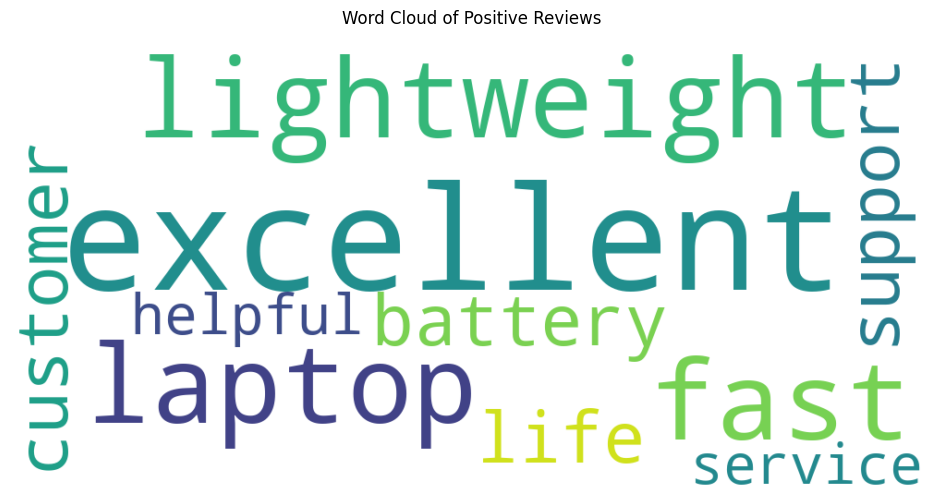

In [20]:
# Word cloud using all positive reviews.
positive_reviews = [
    item["Review"] for item in sentiment_results
    if item["Sentiment"] == "Positive"
]
positive_text = " ".join(positive_reviews)

if positive_text.strip():
    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        stopwords=set(stopwords.words("english"))
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews were found.")

### Interpretation

- **Polarity** ranges from -1 (negative) to +1 (positive).
- **Subjectivity** ranges from 0 (more objective) to 1 (more subjective).
- The rule used is: polarity > 0 → Positive; polarity < 0 → Negative; polarity = 0 → Neutral.
- The word cloud visualizes words in positive reviews after common stopwords are excluded.

TextBlob provides a simple lexicon-based estimate and may not fully understand sarcasm, context, or domain-specific expressions.

## Q6. Text Generation using an LSTM model

An original technology-themed paragraph is used as training text. It is tokenized, converted into input sequences, and used to train a small LSTM language model. The model then generates 2–3 lines from seed phrases.

**Note:** This small corpus keeps the exercise manageable. Generated text may be repetitive or grammatically imperfect; better generation requires a much larger corpus and more training.

In [21]:
training_text = (
    "technology helps people solve problems and share information. "
    "computers process data and support communication. "
    "artificial intelligence learns patterns from examples and helps automate tasks. "
    "cloud computing provides storage and services through the internet. "
    "cybersecurity protects systems and keeps information safe. "
    "students use technology to learn, create projects, and explore new ideas. "
    "responsible technology should respect privacy and improve everyday life. "
    "new tools can support creativity, research, and collaboration. "
    "learning technology requires curiosity, practice, and patience. "
    "people should use digital systems carefully and responsibly."
)
print("Training text:")
print(training_text)
print("\\nWord count:", len(training_text.split()))

Training text:
technology helps people solve problems and share information. computers process data and support communication. artificial intelligence learns patterns from examples and helps automate tasks. cloud computing provides storage and services through the internet. cybersecurity protects systems and keeps information safe. students use technology to learn, create projects, and explore new ideas. responsible technology should respect privacy and improve everyday life. new tools can support creativity, research, and collaboration. learning technology requires curiosity, practice, and patience. people should use digital systems carefully and responsibly.
\nWord count: 83


In [22]:
# 1. Tokenize using Keras Tokenizer and create input sequences.
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for line in training_text.split("."):
    token_list = tokenizer.texts_to_sequences([line.strip()])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

print("Vocabulary size:", total_words)
print("Number of input sequences:", len(input_sequences))
print("Sample sequences:", input_sequences[:5])

Vocabulary size: 64
Number of input sequences: 73
Sample sequences: [[2, 3], [2, 3, 4], [2, 3, 4, 11], [2, 3, 4, 11, 12], [2, 3, 4, 11, 12, 1]]


In [23]:
# 2. Pad sequences and separate predictors (X) and labels (y).
max_sequence_len = max(len(sequence) for sequence in input_sequences)
padded_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Maximum sequence length:", max_sequence_len)
print("X shape:", X.shape)
print("y shape:", y.shape)

Maximum sequence length: 11
X shape: (73, 10)
y shape: (73, 64)


In [24]:
# Build a simple LSTM model.
model = Sequential([
    Embedding(total_words, 64),
    LSTM(100),
    Dense(total_words, activation="softmax")
])
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:
# 3. Train the model.
history = model.fit(X, y, epochs=100, verbose=1)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.0685 - loss: 4.1581
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1370 - loss: 4.1458
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1370 - loss: 4.1333
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1370 - loss: 4.1159
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1370 - loss: 4.0913
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1370 - loss: 4.0403
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1370 - loss: 3.9716
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1370 - loss: 3.8656
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1370 - loss: 3.8780
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1370 - loss: 3.8789
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1370 - loss: 3.8196
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.1370 - lo

In [26]:
# Generate text from a seed phrase.
def generate_text(seed_text, next_words=12):
    generated = seed_text.lower()

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([generated])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )
        predicted_probs = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(predicted_probs))

        output_word = next(
            (word for word, index in tokenizer.word_index.items()
             if index == predicted_id),
            None
        )
        if output_word is None:
            break
        generated += " " + output_word

    return generated

print("Generated line 1:", generate_text("technology helps", 12))
print("Generated line 2:", generate_text("students use", 12))
print("Generated line 3:", generate_text("artificial intelligence", 12))

Generated line 1: technology helps people solve problems and share information information life ideas ideas ideas ideas
Generated line 2: students use technology to learn create projects and explore new ideas ideas ideas ideas
Generated line 3: artificial intelligence learns patterns from examples and helps automate tasks tasks ideas ideas ideas


## Conclusion

This assignment demonstrated text preprocessing and tokenization using regular expressions and NLTK. Stemming and lemmatization were compared, and text features were extracted using Bag of Words and TF-IDF. Jaccard and cosine similarity were applied to compare two technology descriptions. TextBlob was used for sentiment analysis, and a word cloud was generated from positive reviews. Finally, a simple LSTM model was trained on a short paragraph to generate text from seed phrases.

These NLP techniques convert unstructured text into forms that can be analysed computationally. Their results depend on preprocessing, the selected data, and the limitations of each method.